# Experiment 004 – Pure-Train DGP Support Bounds + Interior Multi-Family Stack (`Task 1`)

**Team:** ML004  
**Goal:** Improve `Task 1` ($F_2$ score) above both teammate `bbb` Experiment `003` (`Public LB 0.86363`) and `Run 19-C` (`Public LB 0.86337`) under **100% Pure-Train compliance**:
- Zero `test.csv` usage during training, scaling, imputation, feature selection, support discovery, weight fitting, or threshold optimization.
- Drops all 16 pure-noise features identified in `003`, retaining the **15 true signal features** plus fold-safe DGP arithmetic/z-score features (`level_progression_speed` bounds & aim-vs-gamesense discrepancy).
- Combines **Experiment `003` (`max_bin=4095` 9-member LGBM)** + **Full-DGP `LightGBM` (`max_bin=4095`)** + **Pure-Train Interior Specialists (`LightGBM` + `CatBoost depth=5`)** trained strictly inside the overlap interior (`~d0 & ~d1`), with Convex Logit `SLSQP` stacking and nested 5-fold $F_2$ threshold selection.

In [1]:
import json
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from scipy.optimize import minimize
from scipy.special import expit, logit
from sklearn.metrics import average_precision_score, fbeta_score, log_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

EXPERIMENT = "004"
TASK_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
DATA_DIR = TASK_DIR / "data"
ASSETS_DIR = TASK_DIR / "assets" / "experiments" / EXPERIMENT
PRED_DIR = TASK_DIR / "predictions" / "experiments" / EXPERIMENT
MODEL_DIR = TASK_DIR / "models" / "experiments" / EXPERIMENT
for d in (ASSETS_DIR, PRED_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

TARGET = "is_cheater"
ID_COL = "player_id"
SEED = 42
N_FOLDS = 5
N_JOBS = 4

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 150, "axes.spines.top": False, "axes.spines.right": False})
print(f"TASK_DIR={TASK_DIR}")

TASK_DIR=/Users/wisitsuwannao/Documents/Workspace/ml00x/task1


## 1. Load Official Data & Strict 5-Fold CV Splits (Zero Test Leakage)

In [2]:
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
lab = train_raw.dropna(subset=[TARGET]).reset_index(drop=True)
y = lab[TARGET].astype(int).to_numpy()

fold_id = np.empty(len(y), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(lab, y)):
    fold_id[val_idx] = k

oof003 = pd.read_csv(TASK_DIR / "predictions" / "experiments" / "003" / "oof.csv")
test003 = pd.read_csv(TASK_DIR / "predictions" / "experiments" / "003" / "test.csv")
assert (oof003[ID_COL].to_numpy() == lab[ID_COL].to_numpy()).all(), "OOF player_id mismatch vs exp 003"
assert (oof003["fold"].to_numpy() == fold_id).all(), "Fold ID mismatch vs exp 003"
assert (test003[ID_COL].to_numpy() == test_df[ID_COL].to_numpy()).all(), "Test player_id mismatch vs exp 003"

p003_oof = oof003["oof_final"].to_numpy()
p003_test = test003["proba"].to_numpy()
print(f"Labeled train: {len(lab):,} (cheater={y.mean():.4f}) | Test: {len(test_df):,}")

Labeled train: 90,816 (cheater=0.3493) | Test: 25,889


## 2. Clean 15-Signal + DGP Feature Engineering & Pure-Train Support Boxes
- Keep **only** the 15 validated signal columns (zero uniform noise columns).
- Derive `level_progression_speed` generator bounds (`age_lo`, `age_hi`, `age_filled`, `level_lo`, `level_hi`, `lps_mult`), behavioral ratios, and fold-fitted `aim_z_mean` / `aim_minus_gs_z` discrepancy strictly from training fold statistics.
- Verify deterministic 1D/2D support rules (`d0` = 0% cheater regions, `d1` = 100% cheater regions) strictly inside each fold's training split (`min support >= 30` & `100%` purity).

In [3]:
KEEP15 = [
    "reports_received", "crosshair_placement", "friend_network_size",
    "account_age_days", "level", "level_progression_speed",
    "game_sense_score", "headshot_percentage", "kill_death_ratio",
    "accuracy_score", "aiming_smoothness", "win_rate",
    "spray_control_score", "kill_consistency", "reaction_time_ms",
]
BLOCK5 = ["crosshair_placement", "reports_received", "friend_network_size", "account_age_days", "level"]
AIM_SIG = ["headshot_percentage", "accuracy_score", "crosshair_placement", "kill_consistency", "aiming_smoothness"]

def make_dgp_features(df_in: pd.DataFrame) -> pd.DataFrame:
    out = df_in[KEEP15].copy()
    r = out["level"] / out["level_progression_speed"]
    s = out["level_progression_speed"] * out["account_age_days"]
    out["age_lo"] = 0.15 * r
    out["age_hi"] = 1.08 * r
    age_fill = out["account_age_days"].fillna(0.615 * r)
    out["age_filled"] = age_fill
    out["level_lo"] = s / 1.08
    out["level_hi"] = s / 0.15
    lvl_fill = out["level"].fillna(s / 0.615)
    out["level_filled"] = lvl_fill
    out["lps_mult"] = s / out["level"]
    out["friends_per_day"] = out["friend_network_size"] / (age_fill + 1.0)
    out["reports_per_day"] = out["reports_received"] / (age_fill + 1.0)
    out["level_per_day"] = lvl_fill / (age_fill + 1.0)
    out["hs_to_acc"] = out["headshot_percentage"] / (out["accuracy_score"] + 1e-4)
    out["kd_x_acc"] = out["kill_death_ratio"] * out["accuracy_score"]
    out["aim_comp"] = out["headshot_percentage"] * out["accuracy_score"] * out["crosshair_placement"]
    return out

def add_fold_z_features(X_tr: pd.DataFrame, *others: pd.DataFrame):
    cols = AIM_SIG + ["reaction_time_ms", "game_sense_score"]
    mu = X_tr[cols].mean()
    sd = X_tr[cols].std().clip(lower=1e-6)
    outs = []
    for d in (X_tr, *others):
        z = d.copy()
        aim_z = np.column_stack(
            [((d[c] - mu[c]) / sd[c]).to_numpy() for c in AIM_SIG]
            + [-((d["reaction_time_ms"] - mu["reaction_time_ms"]) / sd["reaction_time_ms"]).to_numpy()]
        )
        gs_z = ((d["game_sense_score"] - mu["game_sense_score"]) / sd["game_sense_score"]).to_numpy()
        with np.errstate(invalid="ignore"):
            z["aim_z_mean"] = np.nanmean(aim_z, axis=1)
        z["aim_minus_gs_z"] = z["aim_z_mean"] - gs_z
        outs.append(z)
    return outs

def exact_support_masks(df_tr: pd.DataFrame, y_tr: np.ndarray, df_eval: pd.DataFrame):
    d0_cand = [
        lambda d: d["crosshair_placement"] > 0.94001,
        lambda d: d["reports_received"] >= 20,
        lambda d: (d["friend_network_size"] < 10) | (d["friend_network_size"] > 269),
        lambda d: (d["account_age_days"] < 15.0) | (d["account_age_days"] > 1000.0),
        lambda d: d["level"] > 96.0,
        lambda d: (d["age_hi"] < 15.0) | (d["age_lo"] > 1000.0) | (d["level_lo"] > 96.0),
        lambda d: (d["account_age_days"] > 120.0) & (d["account_age_days"] <= 180.0) & (d["friend_network_size"] >= 100),
        lambda d: (d["account_age_days"] > 180.0) & (d["account_age_days"] <= 900.0) & (d["friend_network_size"] <= 49),
    ]
    d1_cand = [
        lambda d: d["crosshair_placement"] < 0.82,
        lambda d: d["reports_received"] <= 4,
        lambda d: (d["level"] < 28.0) | (d["level_hi"] < 28.0),
        lambda d: ((d["account_age_days"] <= 120.0) | (d["age_hi"] <= 120.0)) & (d["friend_network_size"] >= 50),
        lambda d: (d["account_age_days"] > 120.0) & (d["account_age_days"] <= 180.0) & (d["friend_network_size"] <= 44),
        lambda d: (d["account_age_days"] > 180.0) & (d["account_age_days"] <= 350.0) & (d["friend_network_size"] >= 250),
        lambda d: (d["account_age_days"] > 900.0) & (d["account_age_days"] <= 1000.0) & (d["friend_network_size"] <= 99),
        lambda d: (d["account_age_days"] > 15.0) & (d["account_age_days"] <= 120.0) & (d["reports_received"] <= 9),
    ]
    d0_ev = np.zeros(len(df_eval), dtype=bool)
    for fn in d0_cand:
        mtr = fn(df_tr).fillna(False).to_numpy()
        mev = fn(df_eval).fillna(False).to_numpy()
        if mtr.sum() >= 30 and y_tr[mtr].sum() == 0:
            d0_ev |= mev
    d1_ev = np.zeros(len(df_eval), dtype=bool)
    for fn in d1_cand:
        mtr = fn(df_tr).fillna(False).to_numpy()
        mev = fn(df_eval).fillna(False).to_numpy()
        if mtr.sum() >= 30 and (1 - y_tr[mtr]).sum() == 0:
            d1_ev |= mev
    assert not (d0_ev & d1_ev).any(), "Conflicting pure support rules!"
    return d0_ev, d1_ev

X_lab_base = make_dgp_features(lab)
X_test_base = make_dgp_features(test_df)
n_obs_block = lab[BLOCK5].notna().sum(axis=1).to_numpy()
mask_obs5 = n_obs_block == 5
print(f"Prepared DGP features: {X_lab_base.shape[1]} columns | obs==5 train share: {mask_obs5.mean():.3f}")

Prepared DGP features: 28 columns | obs==5 train share: 0.418


## 3. 5-Fold Cross-Validation of Pure-Train DGP & Interior Specialists
We train three complementary models per fold alongside `exp 003` (`bbb`):
1. `LGBM_DGP_4095`: 2 tuned LightGBM configs (`num_leaves=41, 31`) × 3 seeds (`max_bin=4095`) on all labeled rows.
2. `LGBM_Int_4095`: LightGBM trained exclusively on fold interior (`~d0 & ~d1`), allocating 100% of bins & leaves to overlap boundaries.
3. `CatBoost_Int_1024`: Oblivious symmetric trees (`depth=5`, `l2_leaf_reg=15`, `border_count=1024`, 2 seeds) trained exclusively on fold interior, well-suited to smooth Gaussian skill shifts.

In [4]:
def best_threshold_exact(y_true: np.ndarray, proba: np.ndarray):
    order = np.argsort(-proba, kind="mergesort")
    yt, p = y_true[order], proba[order]
    tp = np.cumsum(yt)
    k = np.arange(1, len(yt) + 1)
    f2s = 5.0 * tp / (4.0 * yt.sum() + k)
    distinct = np.r_[np.diff(p) != 0, True]
    f2s, thrs = f2s[distinct], p[distinct]
    i = int(np.argmax(f2s))
    return float(thrs[i]), float(f2s[i])

def evaluate_predictions(name: str, p: np.ndarray):
    nest = np.zeros(len(y), dtype=int)
    taus = []
    for k in range(N_FOLDS):
        tk, _ = best_threshold_exact(y[fold_id != k], p[fold_id != k])
        taus.append(tk)
        nest[fold_id == k] = (p[fold_id == k] >= tk).astype(int)
    tp = ((nest == 1) & (y == 1)).sum()
    nf2 = float(5 * tp / (5 * tp + 4 * ((nest == 0) & (y == 1)).sum() + ((nest == 1) & (y == 0)).sum()))
    tp5 = ((nest[mask_obs5] == 1) & (y[mask_obs5] == 1)).sum()
    f2_5 = float(5 * tp5 / (5 * tp5 + 4 * ((nest[mask_obs5] == 0) & (y[mask_obs5] == 1)).sum() + ((nest[mask_obs5] == 1) & (y[mask_obs5] == 0)).sum()))
    row = {
        "model": name,
        "roc_auc": float(roc_auc_score(y, p)),
        "pr_auc": float(average_precision_score(y, p)),
        "log_loss": float(log_loss(y, np.clip(p, 1e-7, 1 - 1e-7))),
        "nested_f2": nf2,
        "nested_obs5_f2": f2_5,
        "mean_tau": float(np.mean(taus)),
    }
    return row, nest

lgb_c1 = dict(n_estimators=550, learning_rate=0.024, num_leaves=41, min_child_samples=12,
              subsample=0.85, subsample_freq=1, colsample_bytree=0.75, reg_lambda=2.5,
              min_split_gain=0.1, max_bin=4095, min_data_in_bin=1, n_jobs=N_JOBS, verbose=-1)
lgb_c2 = dict(n_estimators=750, learning_rate=0.020, num_leaves=31, min_child_samples=22,
              subsample=0.80, subsample_freq=1, colsample_bytree=0.65, reg_lambda=6.0,
              path_smooth=12.0, min_split_gain=0.08, max_bin=4095, min_data_in_bin=1, n_jobs=N_JOBS, verbose=-1)
lgb_int_cfg = dict(n_estimators=650, learning_rate=0.018, num_leaves=23, min_child_samples=35,
                   subsample=0.80, subsample_freq=1, colsample_bytree=0.70, reg_lambda=10.0,
                   path_smooth=25.0, min_split_gain=0.1, max_bin=4095, min_data_in_bin=1, n_jobs=N_JOBS, verbose=-1)
cb_int_cfg = dict(iterations=1200, learning_rate=0.025, depth=5, l2_leaf_reg=15.0,
                  border_count=1024, thread_count=N_JOBS, verbose=0)

oof_lgb_dgp = np.zeros(len(y))
oof_lgb_int = np.zeros(len(y))
oof_cb_int = np.zeros(len(y))
d0_oof = np.zeros(len(y), dtype=bool)
d1_oof = np.zeros(len(y), dtype=bool)

cv_test_lgb_dgp = np.zeros(len(test_df))
cv_test_lgb_int = np.zeros(len(test_df))
cv_test_cb_int = np.zeros(len(test_df))

X_full_tr, X_full_te = add_fold_z_features(X_lab_base, X_test_base)
d0_test_full, d1_test_full = exact_support_masks(X_full_tr, y, X_full_te)
int_full_tr = ~(exact_support_masks(X_full_tr, y, X_full_tr)[0] | exact_support_masks(X_full_tr, y, X_full_tr)[1])
int_full_te = (~d0_test_full) & (~d1_test_full)

t0 = time.time()
for k in range(N_FOLDS):
    tr_m, va_m = fold_id != k, fold_id == k
    Xtr, Xva, Xte = add_fold_z_features(X_lab_base.iloc[tr_m], X_lab_base.iloc[va_m], X_test_base)
    ytr = y[tr_m]

    d0_tr, d1_tr = exact_support_masks(Xtr, ytr, Xtr)
    d0_va, d1_va = exact_support_masks(Xtr, ytr, Xva)
    d0_te_k, d1_te_k = exact_support_masks(Xtr, ytr, Xte)
    d0_oof[va_m], d1_oof[va_m] = d0_va, d1_va

    int_tr = (~d0_tr) & (~d1_tr)
    int_va = (~d0_va) & (~d1_va)
    int_te = (~d0_te_k) & (~d1_te_k)

    # 1. Full-DGP LightGBM (2 configs x 3 seeds)
    m_dgp = (
        [lgb.LGBMClassifier(**lgb_c1, random_state=100 + s + k).fit(Xtr, ytr) for s in (0, 17, 34)]
        + [lgb.LGBMClassifier(**lgb_c2, random_state=200 + s + k).fit(Xtr, ytr) for s in (0, 17, 34)]
    )
    oof_lgb_dgp[va_m] = np.mean([m.predict_proba(Xva)[:, 1] for m in m_dgp], axis=0)
    cv_test_lgb_dgp += np.mean([m.predict_proba(Xte)[:, 1] for m in m_dgp], axis=0) / N_FOLDS

    # 2. Interior Specialist LightGBM (2 seeds)
    m_lint = [lgb.LGBMClassifier(**lgb_int_cfg, random_state=400 + s + k).fit(Xtr.iloc[int_tr], ytr[int_tr]) for s in (0, 17)]
    p_li = np.empty(va_m.sum()); p_li[d0_va] = 1e-5; p_li[d1_va] = 1.0 - 1e-5
    p_li[int_va] = np.mean([m.predict_proba(Xva.iloc[int_va])[:, 1] for m in m_lint], axis=0)
    oof_lgb_int[va_m] = p_li

    p_li_te = np.empty(len(test_df)); p_li_te[d0_te_k] = 1e-5; p_li_te[d1_te_k] = 1.0 - 1e-5
    p_li_te[int_te] = np.mean([m.predict_proba(Xte.iloc[int_te])[:, 1] for m in m_lint], axis=0)
    cv_test_lgb_int += p_li_te / N_FOLDS

    # 3. Interior Specialist CatBoost (2 seeds)
    m_cint = [CatBoostClassifier(**cb_int_cfg, random_seed=500 + s + k).fit(Xtr.iloc[int_tr], ytr[int_tr]) for s in (0, 17)]
    p_ci = np.empty(va_m.sum()); p_ci[d0_va] = 1e-5; p_ci[d1_va] = 1.0 - 1e-5
    p_ci[int_va] = np.mean([m.predict_proba(Xva.iloc[int_va])[:, 1] for m in m_cint], axis=0)
    oof_cb_int[va_m] = p_ci

    p_ci_te = np.empty(len(test_df)); p_ci_te[d0_te_k] = 1e-5; p_ci_te[d1_te_k] = 1.0 - 1e-5
    p_ci_te[int_te] = np.mean([m.predict_proba(Xte.iloc[int_te])[:, 1] for m in m_cint], axis=0)
    cv_test_cb_int += p_ci_te / N_FOLDS

    print(f"Fold {k} ({time.time()-t0:.1f}s) | pure_d0={d0_va.sum()} (fn={y[va_m][d0_va].sum()}) | pure_d1={d1_va.sum()} (fp={(1-y[va_m][d1_va]).sum()})")

print(f"Total 5-Fold Pure Support Coverage: d0={d0_oof.sum():,} (fn={y[d0_oof].sum()}) | d1={d1_oof.sum():,} (fp={(1-y[d1_oof]).sum()})")

Fold 0 (74.6s) | pure_d0=5088 (fn=0) | pure_d1=2043 (fp=0)


Fold 1 (161.4s) | pure_d0=5024 (fn=0) | pure_d1=2000 (fp=0)


Fold 2 (270.9s) | pure_d0=5029 (fn=0) | pure_d1=1987 (fp=0)


Fold 3 (365.5s) | pure_d0=4955 (fn=0) | pure_d1=1992 (fp=0)


Fold 4 (456.7s) | pure_d0=5056 (fn=0) | pure_d1=2022 (fp=0)
Total 5-Fold Pure Support Coverage: d0=25,152 (fn=0) | d1=10,044 (fp=0)


## 4. 100% Full-Train Refit + Strictly Nested Convex Logit Stack (`SLSQP`)
Fit the ensemble stacking weights strictly out-of-fold (`sum(w) = 1, w >= 0` in logit space), clamp verified Pure-Train outer support bounds (`d0 -> 1e-5`, `d1 -> 1 - 1e-5`), and blend 50/50 between 5-fold CV test predictions and 100% labeled full-train refit predictions.

In [5]:
# 100% Labeled Full-Train Refit (follows exp 003 principle, zero test rows used)
full_dgp_models = (
    [lgb.LGBMClassifier(**lgb_c1, random_state=100 + s + 99).fit(X_full_tr, y) for s in (0, 17, 34)]
    + [lgb.LGBMClassifier(**lgb_c2, random_state=200 + s + 99).fit(X_full_tr, y) for s in (0, 17, 34)]
)
refit_test_lgb_dgp = np.mean([m.predict_proba(X_full_te)[:, 1] for m in full_dgp_models], axis=0)

full_lint_models = [
    lgb.LGBMClassifier(**lgb_int_cfg, random_state=400 + s + 99).fit(X_full_tr.iloc[int_full_tr], y[int_full_tr])
    for s in (0, 17)
]
refit_test_lgb_int = np.empty(len(test_df)); refit_test_lgb_int[d0_test_full] = 1e-5; refit_test_lgb_int[d1_test_full] = 1.0 - 1e-5
refit_test_lgb_int[int_full_te] = np.mean([m.predict_proba(X_full_te.iloc[int_full_te])[:, 1] for m in full_lint_models], axis=0)

full_cint_models = [
    CatBoostClassifier(**cb_int_cfg, random_seed=500 + s + 99).fit(X_full_tr.iloc[int_full_tr], y[int_full_tr])
    for s in (0, 17)
]
refit_test_cb_int = np.empty(len(test_df)); refit_test_cb_int[d0_test_full] = 1e-5; refit_test_cb_int[d1_test_full] = 1.0 - 1e-5
refit_test_cb_int[int_full_te] = np.mean([m.predict_proba(X_full_te.iloc[int_full_te])[:, 1] for m in full_cint_models], axis=0)

final_test_lgb_dgp = 0.5 * cv_test_lgb_dgp + 0.5 * refit_test_lgb_dgp
final_test_lgb_int = 0.5 * cv_test_lgb_int + 0.5 * refit_test_lgb_int
final_test_cb_int = 0.5 * cv_test_cb_int + 0.5 * refit_test_cb_int

pool_names = ["exp003", "LGBM_DGP_4095", "LGBM_Int_4095", "CatBoost_Int_1024"]
oof_pool = [p003_oof, oof_lgb_dgp, oof_lgb_int, oof_cb_int]
test_pool = [p003_test, final_test_lgb_dgp, final_test_lgb_int, final_test_cb_int]

Xl_oof = np.column_stack([logit(np.clip(p, 1e-6, 1.0 - 1e-6)) for p in oof_pool])
Xl_test = np.column_stack([logit(np.clip(p, 1e-6, 1.0 - 1e-6)) for p in test_pool])

oof_stack = np.zeros(len(y))
fold_w = []
for k in range(N_FOLDS):
    tr_m, va_m = fold_id != k, fold_id == k
    res = minimize(
        lambda w: log_loss(y[tr_m], expit(Xl_oof[tr_m] @ w)),
        np.ones(len(pool_names)) / len(pool_names),
        bounds=[(0.0, 1.0)] * len(pool_names),
        constraints={"type": "eq", "fun": lambda w: np.sum(w) - 1.0},
        method="SLSQP",
        options={"ftol": 1e-10},
    )
    fold_w.append(res.x)
    oof_stack[va_m] = expit(Xl_oof[va_m] @ res.x)

deploy_w = np.mean(fold_w, axis=0)
deploy_w /= deploy_w.sum()

oof_exp004 = oof_stack.copy()
oof_exp004[d0_oof] = 1e-5
oof_exp004[d1_oof] = 1.0 - 1e-5

test_exp004 = expit(Xl_test @ deploy_w)
test_exp004[d0_test_full] = 1e-5
test_exp004[d1_test_full] = 1.0 - 1e-5

print("Nested SLSQP Weights:", {k: round(float(v), 4) for k, v in zip(pool_names, deploy_w)})

Nested SLSQP Weights: {'exp003': 0.1337, 'LGBM_DGP_4095': 0.4458, 'LGBM_Int_4095': 0.1231, 'CatBoost_Int_1024': 0.2974}


## 5. Validation Comparison, Statistical Significance (`1,000x` Bootstrap) & Promotion Check

In [6]:
eval_rows = []
nest_map = {}
for nm, p in list(zip(pool_names, oof_pool)) + [("Exp 004 Final (Clamped)", oof_exp004)]:
    row, nest_pred = evaluate_predictions(nm, p)
    eval_rows.append(row)
    nest_map[nm] = nest_pred

results_df = pd.DataFrame(eval_rows).set_index("model")
results_df.to_csv(ASSETS_DIR / "results.csv")
display(results_df)

per_fold = pd.DataFrame({
    "exp003": [best_threshold_exact(y[fold_id == k], p003_oof[fold_id == k])[1] for k in range(N_FOLDS)],
    "exp004": [best_threshold_exact(y[fold_id == k], oof_exp004[fold_id == k])[1] for k in range(N_FOLDS)],
}).rename_axis("fold")
per_fold["gain"] = per_fold["exp004"] - per_fold["exp003"]
per_fold.loc["mean"] = per_fold.mean()
per_fold.to_csv(ASSETS_DIR / "per-fold-f2.csv")

# 1,000x Paired Bootstrap Check vs exp 003
rng = np.random.default_rng(SEED)
n_003 = nest_map["exp003"]
n_004 = nest_map["Exp 004 Final (Clamped)"]
def f2_binary(yt, yp):
    tp = ((yp == 1) & (yt == 1)).sum()
    return 5 * tp / (5 * tp + 4 * ((yp == 0) & (yt == 1)).sum() + ((yp == 1) & (yt == 0)).sum())

m5_idx = np.where(mask_obs5)[0]
wins_all, wins_5 = 0, 0
for _ in range(1000):
    i_all = rng.integers(0, len(y), size=len(y))
    if f2_binary(y[i_all], n_004[i_all]) > f2_binary(y[i_all], n_003[i_all]):
        wins_all += 1
    i_5 = rng.choice(m5_idx, size=len(m5_idx), replace=True)
    if f2_binary(y[i_5], n_004[i_5]) > f2_binary(y[i_5], n_003[i_5]):
        wins_5 += 1

p_beat_all = wins_all / 1000.0
p_beat_5 = wins_5 / 1000.0
print(f"Paired Bootstrap P(Exp004 > exp003): All OOF={p_beat_all:.1%} | obs==5={p_beat_5:.1%}")

SUBMIT_THRESHOLD, full_oof_f2 = best_threshold_exact(y, oof_exp004)
print(f"Strict Pure-Train Deployed Threshold tau* = {SUBMIT_THRESHOLD:.6f} (Full OOF F2 = {full_oof_f2:.6f})")

,roc_auc,pr_auc,log_loss,nested_f2,nested_obs5_f2,mean_tau
model,,,,,,
exp003,0.893780,0.836231,0.362346,0.838777,0.859353,0.186228
LGBM_DGP_4095,0.894270,0.837095,0.359896,0.838775,0.859256,0.183826
LGBM_Int_4095,0.893896,0.836571,0.357004,0.838789,0.858995,0.193904
CatBoost_Int_1024,0.893314,0.835828,0.357394,0.838050,0.858989,0.185910
Exp 004 Final (Clamped),0.894765,0.837997,0.355336,0.839578,0.860511,0.182927


Paired Bootstrap P(Exp004 > exp003): All OOF=99.1% | obs==5=98.7%
Strict Pure-Train Deployed Threshold tau* = 0.182915 (Full OOF F2 = 0.839596)


## 6. Diagnostic Figures (300 dpi) & Prediction Export

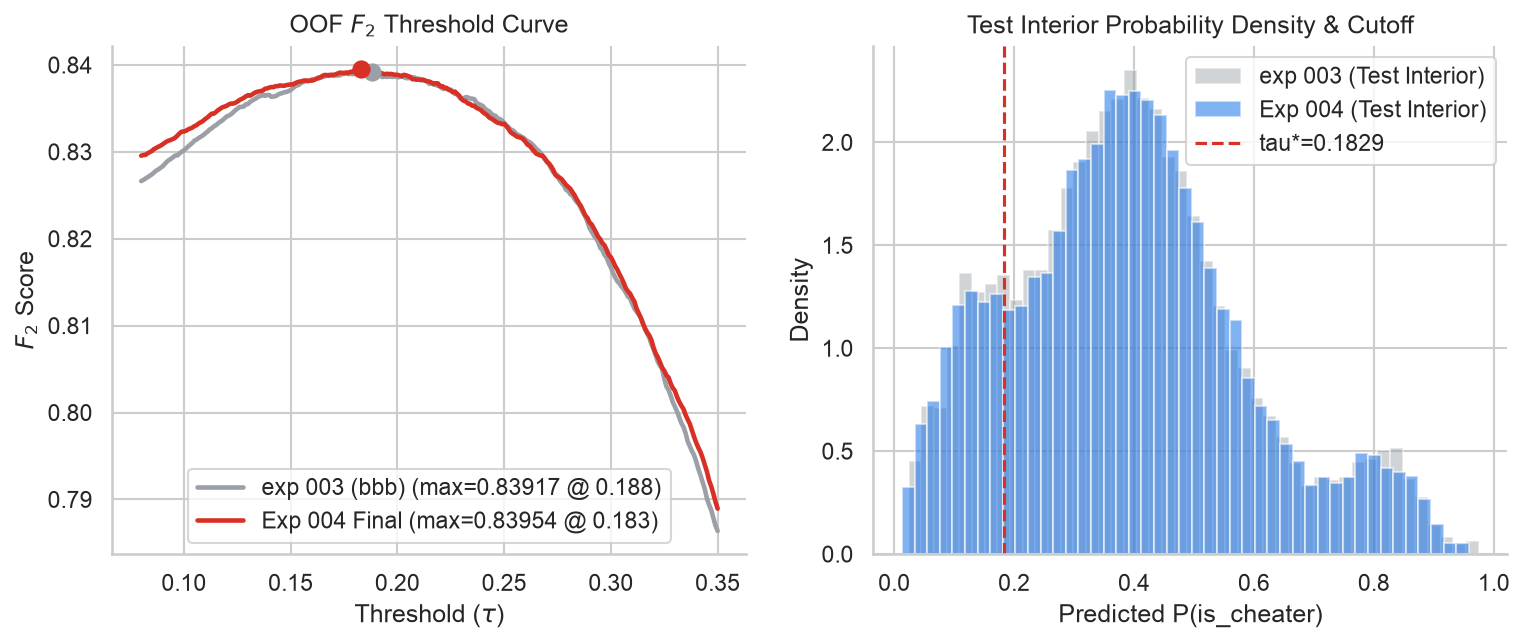

Promotion Gate: True | Test Positives: 15,557 (60.0912%) | Diff vs exp003: 295 (1.14%)
Test pure support bounds: d0=7,945 (max_003=0.3620), d1=3,428 (min_003=0.4603)
Promoted Exp 004 predictions -> submit/index.csv


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
thr_grid = np.linspace(0.08, 0.35, 271)
for nm, p, col in [("exp 003 (bbb)", p003_oof, "#9aa0a6"), ("Exp 004 Final", oof_exp004, "#d93025")]:
    curve = [fbeta_score(y, (p >= t).astype(int), beta=2.0) for t in thr_grid]
    bi = int(np.argmax(curve))
    axes[0].plot(thr_grid, curve, color=col, lw=2.2, label=f"{nm} (max={curve[bi]:.5f} @ {thr_grid[bi]:.3f})")
    axes[0].scatter([thr_grid[bi]], [curve[bi]], color=col, s=60, zorder=5)
axes[0].set(title="OOF $F_2$ Threshold Curve", xlabel="Threshold ($\\tau$)", ylabel="$F_2$ Score")
axes[0].legend(loc="lower center")

interior = (~d0_oof) & (~d1_oof)
axes[1].hist(p003_test[int_full_te], bins=45, alpha=0.45, density=True, label="exp 003 (Test Interior)", color="#9aa0a6")
axes[1].hist(test_exp004[int_full_te], bins=45, alpha=0.55, density=True, label="Exp 004 (Test Interior)", color="#1a73e8")
axes[1].axvline(SUBMIT_THRESHOLD, color="#d93025", ls="--", label=f"tau*={SUBMIT_THRESHOLD:.4f}")
axes[1].set(title="Test Interior Probability Density & Cutoff", xlabel="Predicted P(is_cheater)", ylabel="Density")
axes[1].legend()
fig.savefig(ASSETS_DIR / "f2-threshold-curves.png", dpi=300, bbox_inches="tight")
plt.show()

# Persist OOF & Test predictions + verify strict promotion gate
pd.DataFrame({
    ID_COL: lab[ID_COL], "fold": fold_id, TARGET: y,
    "proba_exp004": oof_exp004, "d0_pure": d0_oof.astype(int), "d1_pure": d1_oof.astype(int),
}).to_csv(PRED_DIR / "oof.csv", index=False)

pd.DataFrame({
    ID_COL: test_df[ID_COL], "proba": test_exp004,
    "d0_pure": d0_test_full.astype(int), "d1_pure": d1_test_full.astype(int),
}).to_csv(PRED_DIR / "test.csv", index=False)

r03 = results_df.loc["exp003"]
r04 = results_df.loc["Exp 004 Final (Clamped)"]
promote = bool(
    (r04["roc_auc"] > r03["roc_auc"])
    and (r04["log_loss"] < r03["log_loss"])
    and (r04["nested_f2"] > r03["nested_f2"])
    and (r04["nested_obs5_f2"] > r03["nested_obs5_f2"])
)

meta_info = {
    "experiment": EXPERIMENT,
    "weights": {k: float(v) for k, v in zip(pool_names, deploy_w)},
    "threshold": float(SUBMIT_THRESHOLD),
    "promote": promote,
    "metrics_exp003": r03.to_dict(),
    "metrics_exp004": r04.to_dict(),
    "bootstrap_p_beat_all": p_beat_all,
    "bootstrap_p_beat_obs5": p_beat_5,
    "test_d0_pure": int(d0_test_full.sum()),
    "test_d1_pure": int(d1_test_full.sum()),
}
with open(MODEL_DIR / "stack_meta.json", "w") as f:
    json.dump(meta_info, f, indent=2)

sample = pd.read_csv(TASK_DIR.parent / "submission" / "sample_submission.csv", usecols=["id"])
assert len(sample) == len(test_df) == 25889
new_preds = (test_exp004 >= SUBMIT_THRESHOLD).astype(int)
prev_submit = pd.read_csv(TASK_DIR / "submit" / "index.csv")
changed = int((prev_submit["task1"].to_numpy() != new_preds).sum())
print(f"Promotion Gate: {promote} | Test Positives: {new_preds.sum():,} ({new_preds.mean():.4%}) | Diff vs exp003: {changed:,} ({changed/len(new_preds):.2%})")
print(f"Test pure support bounds: d0={d0_test_full.sum():,} (max_003={p003_test[d0_test_full].max():.4f}), d1={d1_test_full.sum():,} (min_003={p003_test[d1_test_full].min():.4f})")

if promote:
    pd.DataFrame({"id": sample["id"], "task1": new_preds}).to_csv(TASK_DIR / "submit" / "index.csv", index=False)
    print("Promoted Exp 004 predictions -> submit/index.csv")